# 02. Pemodelan K-Modes Clustering Berbasis Pemisahan Wilayah (Region-Partitioning)
---

### **Tujuan Notebook:**
1. Memuat dataset kategorikal bersih (`01_umkm_clean.csv`, periode 2024, ~266.678 baris).
2. Mempartisi data ke dalam 6 wilayah administrasi DKI Jakarta.
3. Menjalankan algoritma *K-Modes Clustering* dengan fungsi *matching dissimilarity* dan inisialisasi `Cao` pada **2 atribut kategorikal**: `sektor_makro` dan `kelompok_tahun_berdiri`.
4. Menghitung kurva *Elbow* (`cost_` vs $k=2..6$) per wilayah, lalu menentukan jumlah klaster optimal ($k$) **per wilayah** secara objektif dengan aturan *titik terjauh dari garis lurus* (chord/kneedle sederhana) -- tanpa metrik kedua yang dihitung bersamaan dan tanpa penetapan $k$ manual.
5. Melatih model produksi per wilayah dengan $k$ optimal wilayah itu, menyematkan label klaster, dan mengekstrak profil dominan tiap klaster.
6. Menyimpan dataset terklasterisasi ke `data/processed/02_umkm_kmodes_clustered.csv`, ringkasan biaya Elbow ke `data/processed/02b_elbow_costs.csv`, tabel $k$ optimal ke `data/processed/02c_k_optimal.csv`, dan plot kurva Elbow per wilayah ke `data/processed/fig_elbow_per_wilayah.png`.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from kmodes.kmodes import KModes

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

print("Pustaka K-Modes berhasil dimuat.")

Pustaka K-Modes berhasil dimuat.


## 1. Memuat Dataset Hasil Rekayasa Fitur
Memuat dataset `01_umkm_clean.csv` (periode 2024, ~266.678 baris bersih) beserta 2 fitur kategorikal siap olah: `sektor_makro`, `kelompok_tahun_berdiri`.

In [2]:
data_path = os.path.join('..', 'data', 'processed', '01_umkm_clean.csv')
if not os.path.exists(data_path):
    data_path = '01_umkm_clean.csv'

df = pd.read_csv(data_path)
FEATURES = ['sektor_makro', 'kelompok_tahun_berdiri']

print(f"Dataset berhasil dimuat: {len(df):,} baris.")
df[['wilayah'] + FEATURES].head(5)

Dataset berhasil dimuat: 266,678 baris.


,wilayah,sektor_makro,kelompok_tahun_berdiri
0,KOTA ADM. JAKARTA PUSAT,Kriya & Industri Kreatif,Usaha Lama (2020-2021)
1,KOTA ADM. JAKARTA SELATAN,Kuliner & Pangan Olahan,Usaha Lama (2020-2021)
2,KAB. ADM. KEP. SERIBU,"Jasa, Teknologi & Otomotif",Usaha Lama (2020-2021)
3,KOTA ADM. JAKARTA PUSAT,Kuliner & Pangan Olahan,Usaha Lama (2020-2021)
4,KOTA ADM. JAKARTA TIMUR,Kuliner & Pangan Olahan,Usaha Berkembang (2022-2023)


## 2. Fungsi Pemodelan K-Modes per Partisi Wilayah
Algoritma *K-Modes* mengelompokkan data berdasarkan ketidaksamaan pencocokan sederhana (*simple matching dissimilarity*) pada 2 atribut kategorikal (`FEATURES`).

In [3]:
def train_kmodes_region(df_subset, features, n_clusters=3, n_init=5, random_state=42):
    """
    Melatih model K-Modes untuk satu wilayah administrasi pada 2 fitur kategorikal.
    """
    df_reg = df_subset.copy()

    # Matriks fitur kategorikal (2 atribut)
    feature_matrix = df_reg[features].values

    # Inisialisasi K-Modes dengan metode Cao
    km = KModes(
        n_clusters=n_clusters,
        init='Cao',
        n_init=n_init,
        verbose=0,
        random_state=random_state,
        n_jobs=1
    )

    t_start = time.time()
    clusters = km.fit_predict(feature_matrix)
    t_elapsed = time.time() - t_start

    df_reg['cluster'] = clusters

    print(f"Fitting K-Modes selesai ({t_elapsed:.2f} dtk) | k={n_clusters} | Nilai Cost: {km.cost_:,}")
    return df_reg, km

## 3. Kurva Elbow (Cost vs $k$) per Wilayah
Menjalankan K-Modes untuk $k = 2$ hingga $k = 6$ pada **2 fitur** (`sektor_makro`, `kelompok_tahun_berdiri`) di setiap wilayah administrasi, guna mengamati laju penurunan `cost_` (total *matching dissimilarity*) seiring bertambahnya jumlah klaster. Kurva ini jadi dasar tunggal penentuan $k$ optimal per wilayah di Bagian 4 -- tidak ada metrik kedua yang dihitung bersamaan.

=== MENGHITUNG KURVA ELBOW (k=2..6) PER WILAYAH ===

--- Wilayah: KAB. ADM. KEP. SERIBU ---


  k=2 -> Cost: 2,381.0


  k=3 -> Cost: 1,535.0


  k=4 -> Cost: 1,084.0


  k=5 -> Cost: 840.0


...

  k=2 -> Cost: 18,695.0


  k=3 -> Cost: 14,075.0


  k=4 -> Cost: 10,851.0


  k=5 -> Cost: 7,844.0


  k=6 -> Cost: 6,200.0


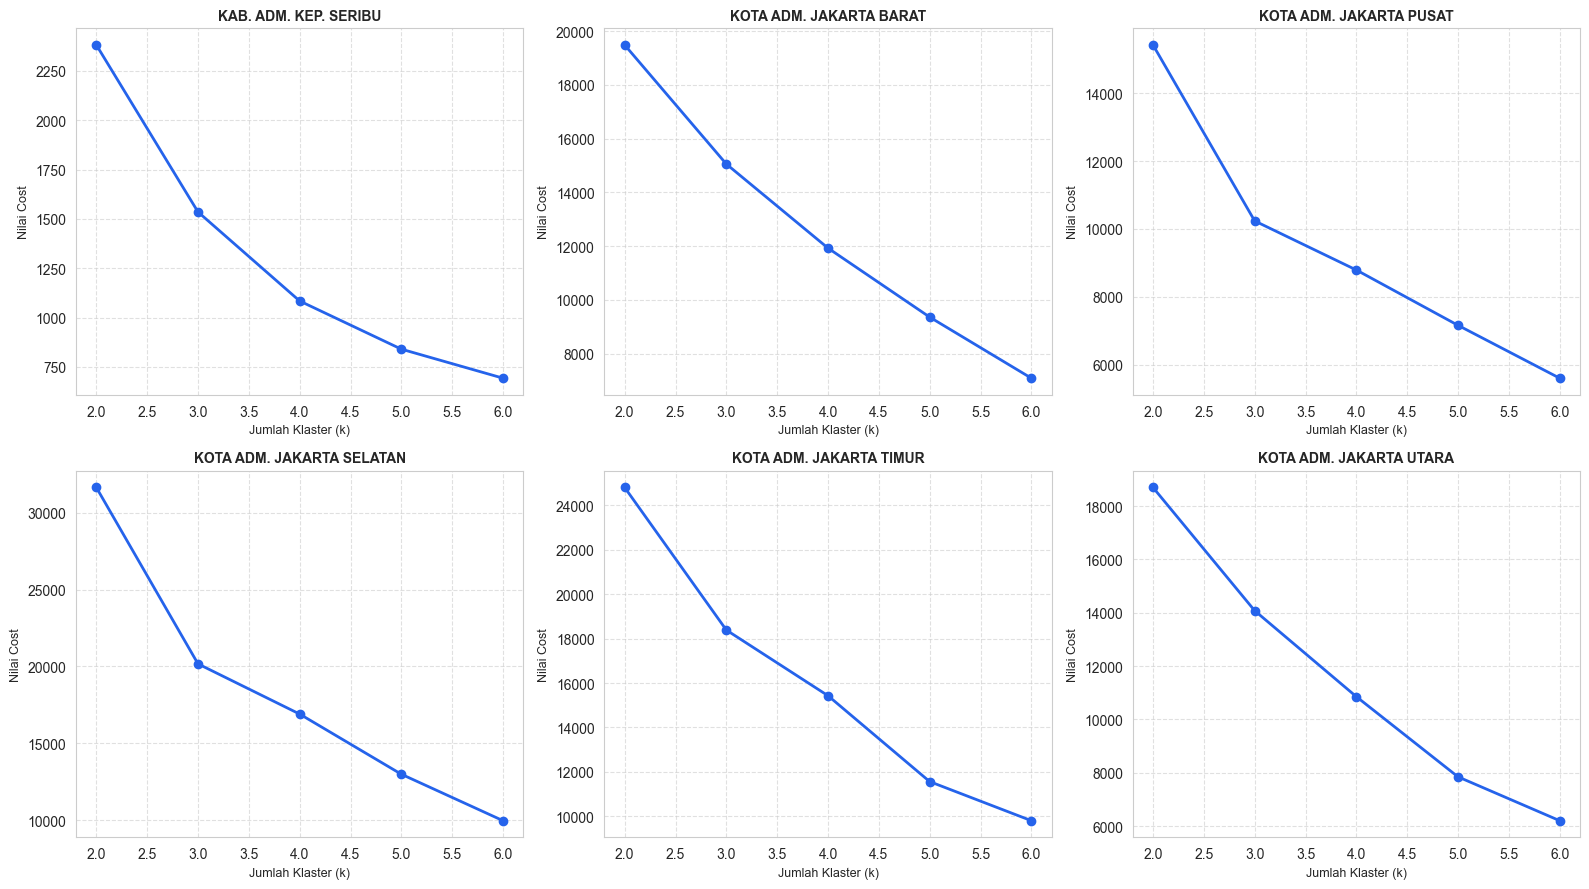


=== KURVA ELBOW SELESAI DIHITUNG UNTUK SELURUH WILAYAH ===


In [4]:
daftar_wilayah = sorted(df['wilayah'].unique().tolist())

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

elbow_records = []

print("=== MENGHITUNG KURVA ELBOW (k=2..6) PER WILAYAH ===")
for idx, wil in enumerate(daftar_wilayah):
    print(f"\n--- Wilayah: {wil} ---")
    df_wil = df[df['wilayah'] == wil]
    X_wil = df_wil[FEATURES].values

    k_vals, costs = [], []
    for k in range(2, 7):
        km = KModes(n_clusters=k, init='Cao', n_init=5, verbose=0, random_state=42, n_jobs=1)
        km.fit(X_wil)
        k_vals.append(k)
        costs.append(km.cost_)
        elbow_records.append({'wilayah': wil, 'k': k, 'cost': km.cost_})
        print(f"  k={k} -> Cost: {km.cost_:,}")

    axes[idx].plot(k_vals, costs, marker='o', color='#2563EB', linewidth=2, markersize=6)
    axes[idx].set_title(f"{wil}", fontsize=10, fontweight='bold')
    axes[idx].set_xlabel("Jumlah Klaster (k)", fontsize=9)
    axes[idx].set_ylabel("Nilai Cost", fontsize=9)
    axes[idx].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

df_elbow = pd.DataFrame(elbow_records)
print("\n=== KURVA ELBOW SELESAI DIHITUNG UNTUK SELURUH WILAYAH ===")

## 4. Penentuan $k$ Optimal per Wilayah & Model Produksi

$k$ optimal **tidak ditetapkan manual**, melainkan dihitung dari kurva Elbow tiap wilayah dengan aturan *titik terjauh dari garis lurus* (chord/kneedle sederhana):

1. Kurva Elbow tiap wilayah ($k=2..6$, Bagian 3) dinormalisasi ke rentang $[0, 1]$ pada kedua sumbu:
   $x = \dfrac{k - k_{min}}{k_{max} - k_{min}}$, $\quad y = \dfrac{cost - cost_{min}}{cost_{max} - cost_{min}}$.
2. Ditarik garis lurus (chord) yang menghubungkan titik pertama ($k=2$, $x=0, y=1$) dan titik terakhir ($k=6$, $x=1, y=0$), yaitu garis $x + y - 1 = 0$.
3. Jarak tiap titik ke garis tersebut: $d = \dfrac{|x + y - 1|}{\sqrt{2}}$.
4. **$k$ optimal = $k$ dengan $d$ terbesar** (titik siku paling menonjol dari garis lurus).
5. Dicatat pula **kekuatan siku** (nilai $d$ maksimum), **$k$ pembanding** ($k$ dengan $d$ terbesar kedua), dan **selisih $d$** antara keduanya, sebagai ukuran seberapa tegas siku tsb.
6. Tidak ada *tie-break* manual maupun ambang buatan sendiri: jika dua $k$ memiliki $d$ persis sama, dipilih $k$ yang lebih kecil dan dicatat di kolom `catatan`.

Seluruh angka di bawah dihitung langsung dari `df_elbow` (bukan angka manual):

In [5]:
print("=== RINGKASAN COST PER k, PER WILAYAH ===")
ringkasan_k = df_elbow.pivot(index='k', columns='wilayah', values='cost')
print(ringkasan_k.round(2))


def tentukan_k_optimal(k_vals, costs):
    """
    Menentukan k optimal dari kurva Elbow dengan aturan "titik terjauh dari garis lurus"
    (chord/kneedle sederhana) yang menghubungkan titik pertama dan terakhir kurva.
    Mengembalikan k optimal, kekuatan siku (d maksimum), k pembanding (d terbesar kedua),
    selisih d keduanya, dan catatan (jika seri, dipilih k lebih kecil).
    """
    k_vals = np.asarray(k_vals, dtype=float)
    costs = np.asarray(costs, dtype=float)

    # Urutkan menurut k menaik, supaya seri otomatis jatuh ke k lebih kecil
    urut = np.argsort(k_vals)
    k_vals, costs = k_vals[urut], costs[urut]

    # Normalisasi kedua sumbu ke [0, 1]
    x = (k_vals - k_vals.min()) / (k_vals.max() - k_vals.min())
    y = (costs - costs.min()) / (costs.max() - costs.min())

    # Jarak tiap titik ke garis penghubung titik pertama (0, 1) dan terakhir (1, 0): x + y - 1 = 0
    d = np.abs(x + y - 1) / np.sqrt(2)

    # Urutan d menurun; kind='stable' mempertahankan urutan k menaik bila nilai d sama
    peringkat = np.argsort(-d, kind='stable')
    i_opt, i_pembanding = peringkat[0], peringkat[1]

    k_optimal = int(k_vals[i_opt])
    k_pembanding = int(k_vals[i_pembanding])
    selisih_d = d[i_opt] - d[i_pembanding]

    if d[i_opt] == d[i_pembanding]:
        k_seri = [int(k) for k in k_vals[d == d[i_opt]]]
        catatan = f"Seri d antara k={k_seri}; dipilih k lebih kecil (k={k_optimal})"
    else:
        catatan = f"k pembanding = {k_pembanding} (selisih d = {selisih_d:.4f})"

    return {
        'k_optimal': k_optimal,
        'kekuatan_siku': round(float(d[i_opt]), 4),
        'k_pembanding': k_pembanding,
        'selisih_d': round(float(selisih_d), 4),
        'catatan': catatan,
        'd_per_k': dict(zip(k_vals.astype(int).tolist(), d.round(4).tolist())),
    }


k_opt_rows = []
d_per_k_rows = []
for wil in daftar_wilayah:
    elbow_wil = df_elbow[df_elbow['wilayah'] == wil].sort_values('k')
    hasil = tentukan_k_optimal(elbow_wil['k'].values, elbow_wil['cost'].values)
    k_opt_rows.append({
        'wilayah': wil,
        'k_optimal': hasil['k_optimal'],
        'kekuatan_siku': hasil['kekuatan_siku'],
        'k_pembanding': hasil['k_pembanding'],
        'selisih_d': hasil['selisih_d'],
        'catatan': hasil['catatan'],
    })
    d_per_k_rows.append(pd.Series(hasil['d_per_k'], name=wil))

df_k_opt = pd.DataFrame(k_opt_rows)

print("\n=== JARAK d TIAP k KE GARIS LURUS (TITIK PERTAMA-TERAKHIR), PER WILAYAH ===")
print(pd.DataFrame(d_per_k_rows).T.rename_axis('k'))

k_opt_path = os.path.join('..', 'data', 'processed', '02c_k_optimal.csv')
df_k_opt.to_csv(k_opt_path, index=False)
print(f"\nTabel k optimal per wilayah berhasil disimpan di: {k_opt_path}")

df_k_opt

=== RINGKASAN COST PER k, PER WILAYAH ===
wilayah  KAB. ADM. KEP. SERIBU  KOTA ADM. JAKARTA BARAT  \
k                                                         
2                       2381.0                  19486.0   
3                       1535.0                  15056.0   
4                       1084.0                  11929.0   
5                        840.0                   9362.0   
6                        693.0                   7090.0   

wilayah  KOTA ADM. JAKARTA PUSAT  KOTA ADM. JAKARTA SELATAN  \
k                                                             
2                        15423.0                    31636.0   
3                        10234.0                    20163.0   
4                         8787.0                    16900.0   
5                         7156.0                    12987.0   
6                         5597.0                     9966.0   

wilayah  KOTA ADM. JAKARTA TIMUR  KOTA ADM. JAKARTA UTARA  
k                                         

,wilayah,k_optimal,kekuatan_siku,k_pembanding,selisih_d,catatan
0,KAB. ADM. KEP. SERIBU,4,0.1898,3,0.0121,k pembanding = 3 (selisih d = 0.0121)
1,KOTA ADM. JAKARTA BARAT,4,0.0775,3,0.0016,k pembanding = 3 (selisih d = 0.0016)
2,KOTA ADM. JAKARTA PUSAT,3,0.1966,4,0.0726,k pembanding = 4 (selisih d = 0.0726)
3,KOTA ADM. JAKARTA SELATAN,3,0.1976,4,0.0703,k pembanding = 4 (selisih d = 0.0703)
4,KOTA ADM. JAKARTA TIMUR,3,0.1258,5,0.0319,k pembanding = 5 (selisih d = 0.0319)
5,KOTA ADM. JAKARTA UTARA,4,0.0903,3,0.0057,k pembanding = 3 (selisih d = 0.0057)


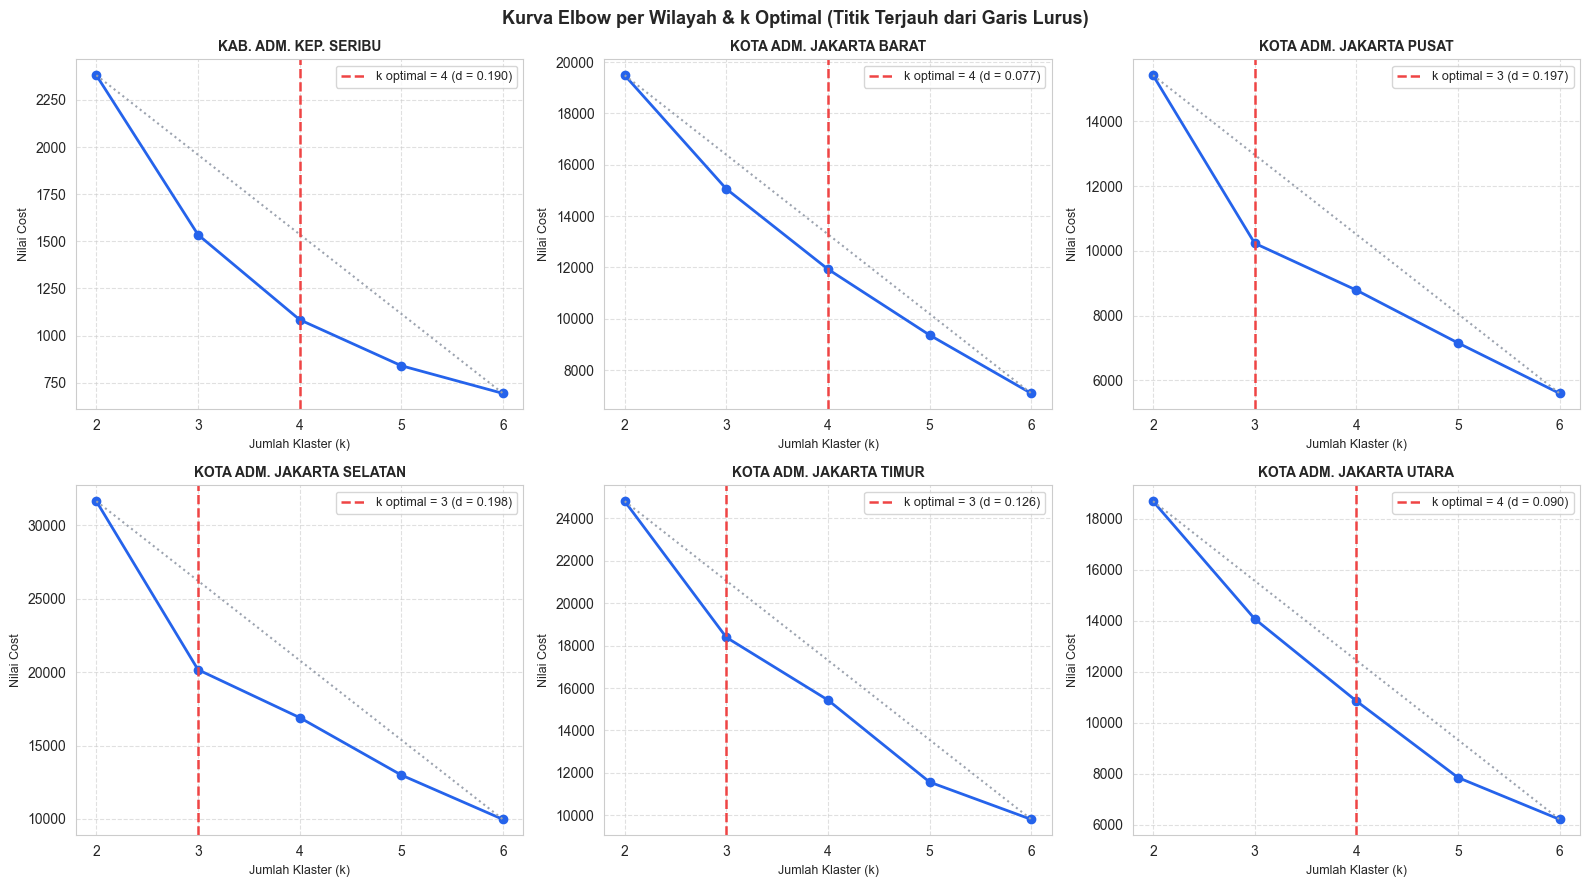

Plot kurva Elbow per wilayah berhasil disimpan di: ..\data\processed\fig_elbow_per_wilayah.png


In [6]:
K_OPT = dict(zip(df_k_opt['wilayah'], df_k_opt['k_optimal']))
SIKU = dict(zip(df_k_opt['wilayah'], df_k_opt['kekuatan_siku']))

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for idx, wil in enumerate(daftar_wilayah):
    elbow_wil = df_elbow[df_elbow['wilayah'] == wil].sort_values('k')
    ax = axes[idx]
    ax.plot(elbow_wil['k'], elbow_wil['cost'], marker='o', color='#2563EB', linewidth=2, markersize=6)
    # Garis lurus penghubung titik pertama-terakhir (acuan aturan titik terjauh)
    ax.plot(elbow_wil['k'].iloc[[0, -1]], elbow_wil['cost'].iloc[[0, -1]], linestyle=':', color='#9CA3AF', linewidth=1.5)
    ax.axvline(K_OPT[wil], color='#EF4444', linestyle='--', linewidth=1.8,
               label=f"k optimal = {K_OPT[wil]} (d = {SIKU[wil]:.3f})")
    ax.set_title(wil, fontsize=10, fontweight='bold')
    ax.set_xlabel("Jumlah Klaster (k)", fontsize=9)
    ax.set_ylabel("Nilai Cost", fontsize=9)
    ax.set_xticks(elbow_wil['k'])
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(fontsize=9, loc='upper right')

fig.suptitle("Kurva Elbow per Wilayah & k Optimal (Titik Terjauh dari Garis Lurus)", fontsize=13, fontweight='bold')
plt.tight_layout()

fig_path = os.path.join('..', 'data', 'processed', 'fig_elbow_per_wilayah.png')
fig.savefig(fig_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"Plot kurva Elbow per wilayah berhasil disimpan di: {fig_path}")

**Hasil -- $k$ optimal per wilayah (aturan titik terjauh dari garis lurus):**

| Wilayah | $k$ optimal | Kekuatan siku ($d$ maks) | $k$ pembanding | Selisih $d$ |
|---|---|---|---|---|
| Kab. Adm. Kep. Seribu | 4 | 0,190 | 3 | 0,012 |
| Kota Adm. Jakarta Barat | 4 | 0,078 | 3 | 0,002 |
| Kota Adm. Jakarta Pusat | 3 | 0,197 | 4 | 0,073 |
| Kota Adm. Jakarta Selatan | 3 | 0,198 | 4 | 0,070 |
| Kota Adm. Jakarta Timur | 3 | 0,126 | 5 | 0,032 |
| Kota Adm. Jakarta Utara | 4 | 0,090 | 3 | 0,006 |

(Angka di tabel ini dibulatkan dari `df_k_opt` di atas; sumber resminya adalah `02c_k_optimal.csv`.)

- **Jakarta Pusat, Jakarta Selatan, Jakarta Timur** -> $k=3$. Di Pusat dan Selatan siku cukup tegas: $d$ pada $k=3$ (~0,20) jauh di atas $k$ pembandingnya.
- **Kep. Seribu** -> $k=4$, dengan siku yang kuat ($d$ ~0,19), meskipun $k=3$ hanya sedikit di bawahnya (selisih ~0,012).
- **Jakarta Barat dan Jakarta Utara** -> $k=4$, **namun siku di kedua wilayah ini lemah**: kekuatan siku hanya ~0,078 (Barat) dan ~0,090 (Utara), dan nilai $d$ pada $k=3$ hampir sama (selisih ~0,002 dan ~0,006). Artinya kurva Elbow kedua wilayah ini relatif landai tanpa siku yang menonjol; $k=4$ dipilih semata karena aturan $d$ terbesar, dan hasil ini perlu dibaca dengan hati-hati (perbedaan $k=3$ vs $k=4$ di sana nyaris setara menurut kurva biaya).

Tidak ada penyesuaian manual terhadap hasil aturan ini. Model final di bawah dilatih ulang per wilayah dengan $k$ = $k$ optimal wilayah tsb (`K_OPT`, dibaca dari `df_k_opt`) dengan `n_init=5` agar pelabelan klaster stabil, lalu disimpan sebagai dataset produksi (dipakai oleh `03_interpretasi_dan_penerapan_ocean.ipynb` dan `app.py`).

In [7]:
K_OPT = dict(zip(df_k_opt['wilayah'], df_k_opt['k_optimal']))
clustered_list = []
model_dict = {}

print("=== MELATIH MODEL PRODUKSI K-MODES (k = k OPTIMAL PER WILAYAH) ===")
for wil in daftar_wilayah:
    print(f"\n--- Wilayah: {wil} (k optimal = {K_OPT[wil]}) ---")
    df_wil = df[df['wilayah'] == wil].copy()

    df_clustered_wil, model_wil = train_kmodes_region(df_wil, FEATURES, n_clusters=K_OPT[wil], n_init=5, random_state=42)

    clustered_list.append(df_clustered_wil)
    model_dict[wil] = model_wil

# Menggabungkan seluruh data yang telah terklasterisasi
df_final = pd.concat(clustered_list, ignore_index=True)
print("\n=== CLUSTERING K-MODES SELURUH WILAYAH SELESAI ===")
print(f"Total baris data terklasterisasi: {len(df_final):,} baris")

# Verifikasi: jumlah klaster per wilayah harus sama dengan k optimal wilayah itu (id 0..k-1)
cek_k = df_final.groupby('wilayah')['cluster'].agg(['nunique', 'min', 'max'])
cek_k['k_optimal'] = cek_k.index.map(K_OPT)
print(cek_k)
assert (cek_k['nunique'] == cek_k['k_optimal']).all()
assert (cek_k['min'] == 0).all() and (cek_k['max'] == cek_k['k_optimal'] - 1).all()

=== MELATIH MODEL PRODUKSI K-MODES (k = k OPTIMAL PER WILAYAH) ===

--- Wilayah: KAB. ADM. KEP. SERIBU (k optimal = 4) ---
Fitting K-Modes selesai (0.12 dtk) | k=4 | Nilai Cost: 1,084.0

--- Wilayah: KOTA ADM. JAKARTA BARAT (k optimal = 4) ---


Fitting K-Modes selesai (1.85 dtk) | k=4 | Nilai Cost: 11,929.0

--- Wilayah: KOTA ADM. JAKARTA PUSAT (k optimal = 3) ---


Fitting K-Modes selesai (1.19 dtk) | k=3 | Nilai Cost: 10,234.0

--- Wilayah: KOTA ADM. JAKARTA SELATAN (k optimal = 3) ---


Fitting K-Modes selesai (2.49 dtk) | k=3 | Nilai Cost: 20,163.0

--- Wilayah: KOTA ADM. JAKARTA TIMUR (k optimal = 3) ---


Fitting K-Modes selesai (1.83 dtk) | k=3 | Nilai Cost: 18,387.0

--- Wilayah: KOTA ADM. JAKARTA UTARA (k optimal = 4) ---


Fitting K-Modes selesai (1.61 dtk) | k=4 | Nilai Cost: 10,851.0

=== CLUSTERING K-MODES SELURUH WILAYAH SELESAI ===
Total baris data terklasterisasi: 266,678 baris
                           nunique  min  max  k_optimal
wilayah                                                
KAB. ADM. KEP. SERIBU            4    0    3          4
KOTA ADM. JAKARTA BARAT          4    0    3          4
KOTA ADM. JAKARTA PUSAT          3    0    2          3
KOTA ADM. JAKARTA SELATAN        3    0    2          3
KOTA ADM. JAKARTA TIMUR          3    0    2          3
KOTA ADM. JAKARTA UTARA          4    0    3          4


## 5. Ekstraksi Modus Pusat Klaster (*Cluster Modes*)
Melihat nilai modus representatif (kombinasi `sektor_makro`, `kelompok_tahun_berdiri`) yang menjadi pusat setiap klaster.

In [8]:
for wil in daftar_wilayah:
    km_model = model_dict[wil]
    print(f"\n==================================================")
    print(f"PUSAT MODUS: {wil}")
    print(f"==================================================")
    for c_id, mode_val in enumerate(km_model.cluster_centroids_):
        print(f"  Klaster {c_id} -> Sektor: '{mode_val[0]}' | Usia Usaha: '{mode_val[1]}'")


PUSAT MODUS: KAB. ADM. KEP. SERIBU
  Klaster 0 -> Sektor: 'Kuliner & Pangan Olahan' | Usia Usaha: 'Usaha Lama (2020-2021)'
  Klaster 1 -> Sektor: 'Agrobisnis, Perikanan & Hayati' | Usia Usaha: 'Usaha Berkembang (2022-2023)'
  Klaster 2 -> Sektor: 'Kuliner & Pangan Olahan' | Usia Usaha: 'Usaha Berkembang (2022-2023)'
  Klaster 3 -> Sektor: 'Agrobisnis, Perikanan & Hayati' | Usia Usaha: 'Usaha Lama (2020-2021)'

PUSAT MODUS: KOTA ADM. JAKARTA BARAT
  Klaster 0 -> Sektor: 'Kuliner & Pangan Olahan' | Usia Usaha: 'Usaha Lama (2020-2021)'
  Klaster 1 -> Sektor: 'Kuliner & Pangan Olahan' | Usia Usaha: 'Usaha Berkembang (2022-2023)'
  Klaster 2 -> Sektor: 'Kuliner & Pangan Olahan' | Usia Usaha: 'Rintisan Baru (2024)'
  Klaster 3 -> Sektor: 'Fesyen & Industri Tekstil' | Usia Usaha: 'Usaha Lama (2020-2021)'

PUSAT MODUS: KOTA ADM. JAKARTA PUSAT
  Klaster 0 -> Sektor: 'Kuliner & Pangan Olahan' | Usia Usaha: 'Usaha Lama (2020-2021)'
  Klaster 1 -> Sektor: 'Kuliner & Pangan Olahan' | Usia Usaha: '

## 6. Penyimpanan Dataset Terklasterisasi & Ringkasan Elbow
Menyimpan dataset akhir (label klaster dengan $k$ optimal per wilayah, id klaster 0..$k$-1 di tiap wilayah) ke `data/processed/02_umkm_kmodes_clustered.csv`, dan ringkasan biaya Elbow ($k=2..6$) ke `data/processed/02b_elbow_costs.csv`. Tabel $k$ optimal (`02c_k_optimal.csv`) dan plot kurva Elbow (`fig_elbow_per_wilayah.png`) sudah disimpan di Bagian 4. Seluruh berkas dipakai kembali oleh `03_interpretasi_dan_penerapan_ocean.ipynb` dan `app.py`.

In [9]:
output_path = os.path.join('..', 'data', 'processed', '02_umkm_kmodes_clustered.csv')
df_final.to_csv(output_path, index=False)
print(f"Dataset hasil K-Modes berhasil disimpan di: {output_path}")

elbow_path = os.path.join('..', 'data', 'processed', '02b_elbow_costs.csv')
df_elbow.to_csv(elbow_path, index=False)
print(f"Ringkasan biaya Elbow berhasil disimpan di: {elbow_path}")

Dataset hasil K-Modes berhasil disimpan di: ..\data\processed\02_umkm_kmodes_clustered.csv
Ringkasan biaya Elbow berhasil disimpan di: ..\data\processed\02b_elbow_costs.csv
